# Fase Process: preparación, limpieza y validación de datos
**Caso:** Nvidia y los controles de exportación de EE.UU. hacia China
**Pregunta guía:** ¿Cómo debe Nvidia, o un inversionista, gestionar su exposición al mercado chino ante los controles de exportación de EE.UU.?

Este notebook es **reproducible**: descarga los datos de fuentes públicas, los limpia, los valida y guarda tablas limpias en `../data/clean/`.
Cada decisión de limpieza tiene un identificador `D-xx` que corresponde a la bitácora de decisiones (`../docs/bitacora_decisiones.md`).

**Fuentes:** SEC EDGAR (XBRL de los 10-K/10-Q de Nvidia y 20-F de ASML), Yahoo Finance vía `yfinance` (precios y estados financieros de rivales chinos), Semiconductor Industry Association (ventas globales, captura manual).

**Uso de IA:** el código de este notebook fue redactado con asistencia de Claude (Anthropic) y revisado por el equipo. Ver `../docs/uso_de_ia.md`.

**Cómo correrlo:** Python 3.10+, `pip install pandas lxml yfinance matplotlib`. Antes de correr, cambia `SEC_USER_AGENT` por el nombre y correo del equipo (la SEC exige identificarse).

In [1]:
import os, time, json, re
from pathlib import Path
import requests
import pandas as pd
import numpy as np
from lxml import etree

BASE   = Path('..').resolve()
RAW    = BASE / 'data' / 'raw'
CLEAN  = BASE / 'data' / 'clean'
FIG    = BASE / 'figuras'
CACHE  = Path(os.environ.get('SEC_CACHE', BASE / 'data' / 'cache_sec'))   # XBRL pesa ~100 MB; no se sube al repositorio
for p in (RAW, CLEAN, FIG, CACHE): p.mkdir(parents=True, exist_ok=True)

SEC_USER_AGENT = os.environ.get('SEC_USER_AGENT', 'Equipo Proyecto Final Ciencia de Datos contacto@ejemplo.com')  # <- cambiar
HDR = {'User-Agent': SEC_USER_AGENT}
FECHA_CORTE = '2026-11-20'   # D-01: fecha de corte de los datos
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

## 1. Nvidia: descarga de 10-K y 10-Q desde SEC EDGAR (XBRL)

In [2]:
def get(url, dest=None, pausa=0.25):
    # Descarga con caché local para no repetir peticiones a la SEC (límite 10 req/s)
    if dest is not None and Path(dest).exists():
        return Path(dest).read_bytes()
    r = requests.get(url, headers=HDR, timeout=60); r.raise_for_status(); time.sleep(pausa)
    if dest is not None: Path(dest).write_bytes(r.content)
    return r.content

def lista_reportes(cik, formas, desde):
    sub = json.loads(get(f'https://data.sec.gov/submissions/CIK{cik:010d}.json', CACHE / f'sub_{cik}.json'))
    r = pd.DataFrame(sub['filings']['recent'])
    r = r[r.form.isin(formas) & (r.reportDate >= desde)].copy()
    r['xbrl'] = r.primaryDocument.str.replace('.htm', '_htm.xml', regex=False)
    r['url'] = [f'https://www.sec.gov/Archives/edgar/data/{cik}/{a.replace("-", "")}/{x}' for a, x in zip(r.accessionNumber, r.xbrl)]
    return r[['form', 'reportDate', 'filingDate', 'accessionNumber', 'xbrl', 'url']]

nvda_rep = lista_reportes(1045810, ['10-K', '10-Q'], '2019-10-01')   # D-02: FY2020 Q3 en adelante
print(len(nvda_rep), 'reportes'); nvda_rep.head()

24 reportes


,form,reportDate,filingDate,accessionNumber,xbrl,url
26,10-Q,2026-07-26,2026-08-26,0001045810-26-000075,nvda-20260726_htm.xml,https://www.sec.gov/Archives/edgar/data/104581...
66,10-Q,2026-04-26,2026-05-20,0001045810-26-000052,nvda-20260426_htm.xml,https://www.sec.gov/Archives/edgar/data/104581...
107,10-K,2026-01-25,2026-02-25,0001045810-26-000021,nvda-20260125_htm.xml,https://www.sec.gov/Archives/edgar/data/104581...
146,10-Q,2025-10-26,2025-11-19,0001045810-25-000230,nvda-20251026_htm.xml,https://www.sec.gov/Archives/edgar/data/104581...
235,10-Q,2025-07-27,2025-08-27,0001045810-25-000209,nvda-20250727_htm.xml,https://www.sec.gov/Archives/edgar/data/104581...


In [3]:
NS = {'x': 'http://www.xbrl.org/2003/instance'}
def hechos_xbrl(xml_bytes, conceptos, archivo):
    # Extrae hechos numéricos de duración (ingresos) con sus dimensiones (región, segmento, etc.)
    root = etree.fromstring(xml_bytes)
    ctx = {}
    for c in root.findall('x:context', NS):
        p = c.find('x:period', NS); s = p.find('x:startDate', NS)
        if s is None: continue           # hechos de instante (balance) no aplican
        dims = {m.get('dimension'): m.text for m in c.iter('{http://xbrl.org/2006/xbrldi}explicitMember')}
        ctx[c.get('id')] = (s.text, p.find('x:endDate', NS).text, dims)
    filas = []
    for el in root:
        if not isinstance(el.tag, str) or el.get('unitRef') is None: continue
        tag = etree.QName(el).localname
        if tag in conceptos and el.get('contextRef') in ctx:
            s, e, dims = ctx[el.get('contextRef')]
            try: v = float(el.text)
            except (TypeError, ValueError): continue
            filas.append(dict(archivo=archivo, concepto=tag, inicio=s, fin=e,
                              dims=';'.join(f'{k}={v_}' for k, v_ in sorted(dims.items())) or 'TOTAL', valor=v))
    return filas

CONCEPTOS_ING = {'Revenues', 'RevenueFromContractWithCustomerExcludingAssessedTax'}
filas = []
for _, r in nvda_rep.iterrows():
    filas += hechos_xbrl(get(r.url, CACHE / r.xbrl), CONCEPTOS_ING, r.xbrl)
nvda_raw = pd.DataFrame(filas).drop_duplicates()
nvda_raw.to_csv(RAW / 'nvda_xbrl_ingresos_raw.csv', index=False)
print(nvda_raw.shape); nvda_raw.dims.value_counts().head(15)

(1122, 6)


dims
TOTAL                                                                                                                               81
srt:StatementGeographicalAxis=country:US                                                                                            78
srt:StatementGeographicalAxis=country:TW                                                                                            78
srt:ProductOrServiceAxis=nvda:DataCenterMember                                                                                      78
srt:StatementGeographicalAxis=nvda:ChinaIncludingHongKongMember                                                                     72
srt:ProductOrServiceAxis=nvda:GamingMember                                                                                          72
srt:ProductOrServiceAxis=nvda:ProfessionalVisualizationMember                                                                       72
srt:ProductOrServiceAxis=nvda:AutomotiveMember    

## 2. Nvidia: transformación a serie trimestral

Decisiones clave (ver bitácora):
- **D-03** Solo se usan las dimensiones de región (EE.UU., Taiwán, China incl. Hong Kong) y de mercado (Data Center, Gaming), más el total.
- **D-04** "China" = `ChinaIncludingHongKongMember`; para FY2019-FY2020 Nvidia usaba `country:CN` con el mismo alcance (los valores coinciden en FY2021-FY2022), así que se unen.
- **D-05 (cambio de metodología)** A partir del 10-Q del 3T FY2026 (oct-2025) Nvidia reporta la región según la **sede del cliente** y no según el **lugar de facturación**, y re-expresó periodos previos. Se guardan **ambas bases** en la columna `base` y nunca se mezclan en una misma serie sin marcarlo.
- **D-06** Si un mismo periodo aparece en varios reportes con la misma base, se usa el valor del reporte más reciente.
- **D-07** Nvidia no publica 10-Q del 4.º trimestre: 4T = anual (10-K) − acumulado de 9 meses (10-Q del 3T), dentro de la misma base.
- **D-08** "Otros países" = total − EE.UU. − Taiwán − China (las categorías residuales cambiaron de nombre con los años).

In [4]:
MAPA = {
    'TOTAL': 'total',
    'srt:StatementGeographicalAxis=country:US': 'eeuu',
    'srt:StatementGeographicalAxis=country:TW': 'taiwan',
    'srt:StatementGeographicalAxis=nvda:ChinaIncludingHongKongMember': 'china',
    'srt:StatementGeographicalAxis=country:CN': 'china',                     # D-04
    'srt:ProductOrServiceAxis=nvda:DataCenterMember': 'data_center',
    'srt:ProductOrServiceAxis=nvda:GamingMember': 'gaming',
}
GEO = {'eeuu', 'taiwan', 'china'}
CAMBIO_BASE = 'nvda-20251026_htm.xml'     # primer reporte con base "sede del cliente" (D-05)

d = nvda_raw[nvda_raw.dims.isin(MAPA)].copy()
d['variable'] = d.dims.map(MAPA)
d['inicio'] = pd.to_datetime(d.inicio); d['fin'] = pd.to_datetime(d.fin)
d['dias'] = (d.fin - d.inicio).dt.days
d['tipo'] = pd.cut(d.dias, [0, 100, 200, 300, 400], labels=['T', 'S', '9M', 'A'])
d['base'] = np.where(d.variable.isin(GEO), np.where(d.archivo >= CAMBIO_BASE, 'sede_cliente', 'facturacion'), 'n/a')
# D-06: valor del reporte más reciente por periodo y base
d = d.sort_values('archivo').groupby(['variable', 'base', 'inicio', 'fin', 'tipo'], observed=True, as_index=False).last()

def etiqueta_fiscal(fin):
    # El año fiscal de Nvidia termina a fines de enero: FY = año calendario + 1 salvo en enero
    fy = fin.year if fin.month <= 2 else fin.year + 1
    q = {4: 1, 5: 1, 7: 2, 8: 2, 10: 3, 11: 3, 1: 4, 2: 4}[fin.month]
    return fy, q

trim = d[d.tipo == 'T'][['variable', 'base', 'inicio', 'fin', 'valor', 'archivo']].assign(origen='reportado')
# D-07: derivar el 4T
anual = d[d.tipo == 'A']; nueve = d[d.tipo == '9M']
q4 = anual.merge(nueve, on=['variable', 'base'], suffixes=('_a', '_9'))
q4 = q4[q4.inicio_a == q4.inicio_9]
q4 = pd.DataFrame({'variable': q4.variable, 'base': q4.base, 'inicio': q4.fin_9 + pd.Timedelta(days=1),
                   'fin': q4.fin_a, 'valor': q4.valor_a - q4.valor_9, 'archivo': q4.archivo_a, 'origen': 'derivado_anual_menos_9M'})
trim = pd.concat([trim, q4], ignore_index=True)
trim[['anio_fiscal', 'trimestre']] = trim.fin.apply(lambda f: pd.Series(etiqueta_fiscal(f)))
trim['periodo'] = 'FY' + trim.anio_fiscal.astype(str) + '-Q' + trim.trimestre.astype(str)
trim['valor_musd'] = trim.valor / 1e6
trim = trim.sort_values(['variable', 'base', 'fin']).reset_index(drop=True)
trim.groupby(['variable', 'base']).periodo.agg(['min', 'max', 'count'])

min        max  count
variable    base                                     
china       facturacion   FY2020-Q3  FY2026-Q2     24
            sede_cliente  FY2025-Q3  FY2027-Q2      8
data_center n/a           FY2020-Q3  FY2027-Q2     28
eeuu        facturacion   FY2020-Q3  FY2026-Q2     24
            sede_cliente  FY2025-Q3  FY2027-Q2      8
gaming      n/a           FY2020-Q3  FY2026-Q4     26
taiwan      facturacion   FY2020-Q3  FY2026-Q2     24
            sede_cliente  FY2025-Q3  FY2027-Q2      8
total       n/a           FY2020-Q3  FY2027-Q2     28

In [5]:
# Tabla ancha: una fila por trimestre y base geográfica
def ancha(base):
    g = trim[(trim.base == base) | (trim.base == 'n/a')]
    w = g.pivot_table(index=['anio_fiscal', 'trimestre', 'periodo', 'fin'], columns='variable', values='valor_musd').reset_index()
    w = w.dropna(subset=['china'])
    w['otros'] = w.total - w.eeuu - w.taiwan - w.china            # D-08
    w['pct_china'] = 100 * w.china / w.total
    w['pct_eeuu'] = 100 * w.eeuu / w.total
    w['pct_dc'] = 100 * w.data_center / w.total
    w.insert(4, 'base', base)
    return w

nvda_q = pd.concat([ancha('facturacion'), ancha('sede_cliente')], ignore_index=True)
nvda_q[['periodo', 'base', 'total', 'china', 'pct_china', 'data_center']].tail(12)

variable,periodo,base,total,china,pct_china,data_center
20,FY2025-Q3,facturacion,"35,082.00","5,416.00",15.44,"30,771.00"
21,FY2025-Q4,facturacion,"39,331.00","5,534.00",14.07,"35,580.00"
22,FY2026-Q1,facturacion,"44,062.00","5,522.00",12.53,"39,112.00"
23,FY2026-Q2,facturacion,"46,743.00","2,769.00",5.92,"41,096.00"
24,FY2025-Q3,sede_cliente,"35,082.00","8,142.00",23.21,"30,771.00"
25,FY2025-Q4,sede_cliente,"39,331.00","7,818.00",19.88,"35,580.00"
26,FY2026-Q1,sede_cliente,"44,062.00","9,659.00",21.92,"39,112.00"
27,FY2026-Q2,sede_cliente,"46,743.00","3,985.00",8.53,"41,096.00"
28,FY2026-Q3,sede_cliente,"57,006.00","2,973.00",5.22,"51,215.00"
29,FY2026-Q4,sede_cliente,"68,127.00","3,060.00",4.49,"62,314.00"


## 3. Validaciones

In [6]:
chk = []
# V1: regiones suman el total (otros no debe ser negativo)
chk.append(('V1 otros >= 0 (regiones no exceden total)', (nvda_q.otros >= -1).all()))
# V2: el 4T derivado no es negativo
chk.append(('V2 4T derivado >= 0', (trim[trim.origen != 'reportado'].valor >= 0).all()))
# V3: suma de 4 trimestres = anual reportado (total)
tq = trim[(trim.variable == 'total')].groupby('anio_fiscal').valor.agg(['sum', 'count'])
ta = d[(d.variable == 'total') & (d.tipo == 'A')].assign(anio_fiscal=lambda x: x.fin.dt.year).set_index('anio_fiscal').valor
comp = tq[tq['count'] == 4].join(ta.rename('anual'), how='inner')
chk.append(('V3 suma trimestral = anual (total)', np.allclose(comp['sum'], comp.anual, rtol=1e-6)))
# V4: Data Center <= total
chk.append(('V4 data_center <= total', (nvda_q.data_center.dropna() <= nvda_q.total[nvda_q.data_center.notna()]).all()))
# V5: sin trimestres faltantes en base facturación entre FY2020-Q3 y FY2026-Q2
fact = nvda_q[nvda_q.base == 'facturacion']
chk.append(('V5 serie facturación completa', len(fact) == 24 and fact.periodo.is_unique))
# V6: cotejo manual contra el texto del 10-K FY2026 (China FY2026 = 19,677 MUSD; total = 215,938 MUSD)
a26 = d[(d.tipo == 'A') & (d.fin == '2026-01-25')].set_index('variable').valor / 1e6
chk.append(('V6 cotejo 10-K FY2026', round(a26['china']) == 19677 and round(a26['total']) == 215938))
val = pd.DataFrame(chk, columns=['validacion', 'ok']); print(val.to_string(index=False))
assert val.ok.all(), 'Alguna validación falló'

                               validacion   ok
V1 otros >= 0 (regiones no exceden total) True
                      V2 4T derivado >= 0 True
       V3 suma trimestral = anual (total) True
                  V4 data_center <= total True
            V5 serie facturación completa True
                    V6 cotejo 10-K FY2026 True


In [7]:
# Tabla anual (ambas bases) para el resumen del caso
an = d[d.tipo == 'A'].copy(); an['anio_fiscal'] = an.fin.dt.year
an = an.pivot_table(index=['anio_fiscal'], columns=['variable', 'base'], values='valor') / 1e6
an.columns = [f'{v}' if b == 'n/a' else f'{v}_{b}' for v, b in an.columns]
for b in ['facturacion', 'sede_cliente']:
    if f'china_{b}' in an: an[f'pct_china_{b}'] = 100 * an[f'china_{b}'] / an.total
an = an.reset_index(); an.round(1)

,anio_fiscal,china_facturacion,china_sede_cliente,data_center,eeuu_facturacion,eeuu_sede_cliente,gaming,taiwan_facturacion,taiwan_sede_cliente,total,pct_china_facturacion,pct_china_sede_cliente
0,2019,"2,801.00",NaN,"2,932.00","1,506.00",NaN,"6,246.00","3,360.00",NaN,"11,716.00",23.90,NaN
1,2020,"2,731.00",NaN,"2,983.00",886.00,NaN,"5,518.00","3,025.00",NaN,"10,918.00",25.00,NaN
2,2021,"3,886.00",NaN,"6,696.00","3,214.00",NaN,"7,759.00","4,531.00",NaN,"16,675.00",23.30,NaN
3,2022,"7,111.00",NaN,"10,613.00","4,349.00",NaN,"12,462.00","8,544.00",NaN,"26,914.00",26.40,NaN
4,2023,"5,785.00",NaN,"15,005.00","8,292.00",NaN,"9,067.00","6,986.00",NaN,"26,974.00",21.40,NaN
5,2024,"10,306.00","12,330.00","47,525.00","26,966.00","31,533.00","10,447.00","13,405.00","14,912.00","60,922.00",16.90,20.20
6,2025,"17,108.00","25,048.00","115,186.00","61,257.00","77,482.00","11,350.00","20,573.00","23,600.00","130,497.00",13.10,19.20
7,2026,NaN,"19,677.00","193,737.00",NaN,"149,617.00","16,042.00",NaN,"42,345.00","215,938.00",NaN,9.10


## 4. ASML (recuadro comparativo): ingresos por región desde el 20-F

In [8]:
asml_rep = lista_reportes(937966, ['20-F'], '2019-01-01')
filas = []
for _, r in asml_rep.iterrows():
    filas += hechos_xbrl(get(r.url, CACHE / r.xbrl), {'RevenueFromContractWithCustomerExcludingAssessedTax'}, r.xbrl)
a = pd.DataFrame(filas).drop_duplicates()
a = a[(a.dims == 'TOTAL') | a.dims.str.contains('StatementGeographicalAxis=country:CN')]
a['variable'] = np.where(a.dims == 'TOTAL', 'total', 'china')
a['anio'] = pd.to_datetime(a.fin).dt.year
a = a[(pd.to_datetime(a.fin) - pd.to_datetime(a.inicio)).dt.days > 350]
a = a.sort_values('archivo').groupby(['anio', 'variable']).valor.last().unstack() / 1e6   # D-06
a['pct_china'] = 100 * a.china / a.total
asml = a.reset_index().rename(columns={'total': 'total_meur', 'china': 'china_meur'})
asml

variable,anio,china_meur,total_meur,pct_china
0,2017,919.50,"8,962.70",10.26
1,2018,"1,842.80","10,944.00",16.84
2,2019,"1,377.70","11,820.00",11.66
3,2020,"2,324.40","13,978.50",16.63
4,2021,"2,740.80","18,611.00",14.73
5,2022,"2,916.00","21,173.40",13.77
6,2023,"7,251.80","27,558.50",26.31
7,2024,"10,195.10","28,262.90",36.07
8,2025,"9,519.70","32,667.30",29.14


## 5. Precios diarios (Yahoo Finance)
- **D-09** Se usa el precio de cierre **ajustado** (incorpora splits y dividendos; Nvidia hizo split 4:1 en 2021 y 10:1 en 2024).
- **D-10** Benchmark de mercado: S&P 500 (`^GSPC`); benchmark sectorial: índice de semiconductores de Filadelfia (`^SOX`).
- **D-11** Las acciones chinas cotizan en otros calendarios y monedas; se guardan aparte y no se mezclan con los rendimientos de EE.UU.

In [9]:
import yfinance as yf
US  = ['NVDA', 'AMD', 'ASML', '^GSPC', '^SOX']
CN  = ['688256.SS', '688041.SS', '688981.SS']        # Cambricon, Hygon, SMIC (Shanghái, CNY)
def bajar(tickers):
    p = yf.download(tickers, start='2019-01-01', end=FECHA_CORTE, auto_adjust=False, progress=False)['Adj Close']
    return p.dropna(how='all')
px_us = bajar(US); px_cn = bajar(CN)
px_us.to_csv(RAW / 'precios_ajustados_eeuu_raw.csv'); px_cn.to_csv(RAW / 'precios_ajustados_china_raw.csv')
print('Faltantes EE.UU. por columna:\n', px_us.isna().sum())

Crumb fetch rate-limited (HTTP 429), continuing without crumb


Faltantes EE.UU. por columna:
 Ticker
AMD      0
ASML     0
NVDA     0
^GSPC    0
^SOX     0
dtype: int64


In [10]:
# D-12: en EE.UU. todas las series comparten calendario; se eliminan días con algún faltante (feriados con dato parcial)
px = px_us.dropna().rename(columns={'^GSPC': 'SP500', '^SOX': 'SOX'})
ret = np.log(px).diff().dropna()           # rendimientos logarítmicos diarios
ret.columns = [f'r_{c}' for c in ret.columns]
precios = px.join(ret).reset_index().rename(columns={'Date': 'fecha'})
# Validación: ningún rendimiento diario absurdo (> 50%) que indique un split mal ajustado
assert (ret.abs() < 0.5).all().all(), 'Revisar splits'
precios.tail(3)

,fecha,AMD,ASML,NVDA,SP500,SOX,r_AMD,r_ASML,r_NVDA,r_SP500,r_SOX
1980,2026-11-17,503.41,"1,383.11",155.46,"7,340.53","9,642.88",-0.00,-0.02,-0.00,-0.01,0.00
1981,2026-11-18,530.14,"1,395.27",150.96,"7,323.63","9,652.80",0.05,0.01,-0.03,-0.00,0.00
1982,2026-11-19,489.19,"1,356.20",145.98,"7,175.83","9,419.72",-0.08,-0.03,-0.03,-0.02,-0.02


## 6. Calendario de eventos (para el estudio de eventos en Analyze)
- **D-13** Fecha de evento = primer día hábil en que el mercado pudo reaccionar. Si el anuncio fue después del cierre, se usa el día siguiente (columna `fecha_reaccion`). Cuando la hora exacta es incierta, la ventana (-1, +1) del estudio de eventos cubre la ambigüedad.

In [11]:
eventos = pd.DataFrame([
  ('E1','2022-08-31','2022-09-01','EE.UU.','Nvidia revela (8-K) que el gobierno exige licencia para vender A100/H100 a China','Nvidia 8-K, 31-ago-2022'),
  ('E2','2022-10-07','2022-10-07','EE.UU.','BIS publica las reglas del 7 de octubre sobre chips avanzados y equipo para China','BIS, 2022'),
  ('E3','2023-10-17','2023-10-17','EE.UU.','BIS actualiza las reglas: quedan restringidos A800/H800 y L40S','BIS, 2023; Nvidia 10-K FY2024'),
  ('E4','2024-12-09','2024-12-09','China','SAMR (regulador de competencia chino) abre investigación antimonopolio a Nvidia','Reuters, 2024'),
  ('E5','2025-01-13','2025-01-13','EE.UU.','Se anuncia la regla "AI Diffusion" (licencias a nivel mundial; rescindida en mayo 2025)','Nvidia 10-K FY2026'),
  ('E6','2025-04-15','2025-04-16','EE.UU.','Nvidia revela que el H20 requiere licencia; cargo de 5,500 MUSD (final: 4,500)','Nvidia 8-K, 15-abr-2025'),
  ('E7','2025-07-14','2025-07-15','EE.UU.','Nvidia anuncia que retomará ventas de H20 a China','Nvidia, 2025'),
  ('E8','2025-08-11','2025-08-11','EE.UU.','Se reporta acuerdo para que el gobierno de EE.UU. reciba 15% de ventas de H20 en China','Nvidia 10-Q 3T FY2026'),
  ('E9','2025-09-17','2025-09-17','China','La CAC pide a empresas chinas dejar de comprar chips de Nvidia (RTX Pro 6000D/H20)','Financial Times vía Bloomberg, 2025'),
  ('E10','2025-12-08','2025-12-08','EE.UU.','Trump autoriza exportar H200 a China con 25% para el gobierno de EE.UU.','Semafor / Bloomberg, 8-dic-2025'),
  ('E11','2026-01-14','2026-01-14','China','Aduanas chinas reciben instrucción de no dejar entrar el H200','Reuters vía Business Day, 14-ene-2026'),
  ('E12','2026-08-19','2026-08-19','China','China permite entregas limitadas de H200 caso por caso (ByteDance, Tencent)','Business Standard, 19-ago-2026'),
], columns=['id','fecha_anuncio','fecha_reaccion','origen','descripcion','fuente'])
eventos['fecha_reaccion'] = pd.to_datetime(eventos.fecha_reaccion)
# Validación: cada fecha de reacción debe ser día hábil con dato de precio
dias = set(precios.fecha)
eventos['dia_habil_ok'] = eventos.fecha_reaccion.isin(dias)
eventos[['id','fecha_reaccion','dia_habil_ok','descripcion']]

,id,fecha_reaccion,dia_habil_ok,descripcion
0,E1,2022-09-01,True,Nvidia revela (8-K) que el gobierno exige lice...
1,E2,2022-10-07,True,BIS publica las reglas del 7 de octubre sobre ...
2,E3,2023-10-17,True,BIS actualiza las reglas: quedan restringidos ...
3,E4,2024-12-09,True,SAMR (regulador de competencia chino) abre inv...
4,E5,2025-01-13,True,"Se anuncia la regla ""AI Diffusion"" (licencias ..."
5,E6,2025-04-16,True,Nvidia revela que el H20 requiere licencia; ca...
6,E7,2025-07-15,True,Nvidia anuncia que retomará ventas de H20 a China
7,E8,2025-08-11,True,Se reporta acuerdo para que el gobierno de EE....
8,E9,2025-09-17,True,La CAC pide a empresas chinas dejar de comprar...
9,E10,2025-12-08,True,Trump autoriza exportar H200 a China con 25% p...


## 7. Rivales chinos y mercado global
- **D-14** Ingresos de Cambricon, Hygon y SMIC tomados de Yahoo Finance (`yfinance`), que reproduce los estados financieros publicados. Es una **fuente secundaria**: se cotejó Cambricon 2023-2024 con su reporte anual (709 y 1,174 millones de CNY) y SMIC 2024 (8,030 MUSD). Se detectó que `yfinance` etiqueta mal la moneda de SMIC (dice CNY, pero SMIC reporta en USD) y se corrigió a mano. Huawei no cotiza y no desglosa Ascend, así que se describe de forma cualitativa.
- **D-15** Ventas globales de semiconductores: cifras anuales de los comunicados de la SIA (datos WSTS), capturadas a mano porque el sitio no ofrece API.

In [12]:
rivales = []
for t, nombre in [('688256.SS','Cambricon'), ('688041.SS','Hygon'), ('0981.HK','SMIC')]:
    tk = yf.Ticker(t); inc = tk.income_stmt
    moneda = tk.info.get('financialCurrency', 'NA')
    if nombre == 'SMIC': moneda = 'USD'   # D-14: SMIC reporta en USD; yfinance la etiqueta como CNY (verificado vs. reporte anual 2024: 8,030 MUSD)
    for f, v in inc.loc['Total Revenue'].dropna().items():
        rivales.append(dict(empresa=nombre, ticker=t, anio=f.year, ingresos_millones=v/1e6, moneda=moneda))
rivales = pd.DataFrame(rivales).sort_values(['empresa','anio'])
rivales['crec_anual_pct'] = rivales.groupby('empresa').ingresos_millones.pct_change()*100
rivales

,empresa,ticker,anio,ingresos_millones,moneda,crec_anual_pct
3,Cambricon,688256.SS,2022,729.03,CNY,NaN
2,Cambricon,688256.SS,2023,709.39,CNY,-2.70
1,Cambricon,688256.SS,2024,"1,174.46",CNY,65.56
0,Cambricon,688256.SS,2025,"6,497.20",CNY,453.21
7,Hygon,688041.SS,2022,"5,125.27",CNY,NaN
6,Hygon,688041.SS,2023,"6,012.00",CNY,17.30
5,Hygon,688041.SS,2024,"9,162.15",CNY,52.40
4,Hygon,688041.SS,2025,"14,376.89",CNY,56.92
11,SMIC,0981.HK,2022,"7,273.28",USD,NaN
10,SMIC,0981.HK,2023,"6,321.56",USD,-13.09


In [13]:
sia = pd.DataFrame({'anio': [2019, 2020, 2021, 2022, 2023, 2024, 2025],
                    'ventas_globales_musd': [412_100, 439_000, 555_900, 574_100, 526_800, 627_600, 791_700],
                    'fuente': ['SIA, 2020', 'SIA, 2021', 'SIA, 2022', 'SIA, 2023', 'SIA, 2024', 'SIA, 2025', 'SIA, 2026']})
sia['crec_pct'] = sia.ventas_globales_musd.pct_change()*100
sia

,anio,ventas_globales_musd,fuente,crec_pct
0,2019,412100,"SIA, 2020",NaN
1,2020,439000,"SIA, 2021",6.53
2,2021,555900,"SIA, 2022",26.63
3,2022,574100,"SIA, 2023",3.27
4,2023,526800,"SIA, 2024",-8.24
5,2024,627600,"SIA, 2025",19.13
6,2025,791700,"SIA, 2026",26.15


## 8. Exportar tablas limpias y diccionario de datos

In [14]:
nvda_q.round({c: 3 for c in nvda_q.select_dtypes('number').columns}).to_csv(CLEAN / 'nvda_ingresos_trimestrales.csv', index=False)
trim[['periodo','anio_fiscal','trimestre','inicio','fin','variable','base','valor_musd','origen','archivo']] \
    .to_csv(CLEAN / 'nvda_ingresos_trimestrales_largo.csv', index=False)
an.round(3).to_csv(CLEAN / 'nvda_ingresos_anuales.csv', index=False)
asml.round(3).to_csv(CLEAN / 'asml_ingresos_china_anual.csv', index=False)
precios.to_csv(CLEAN / 'precios_diarios_eeuu.csv', index=False)
px_cn.reset_index().rename(columns={'Date':'fecha'}).to_csv(CLEAN / 'precios_diarios_rivales_china.csv', index=False)
eventos.to_csv(CLEAN / 'eventos_controles_exportacion.csv', index=False)
rivales.round(3).to_csv(CLEAN / 'rivales_china_ingresos_anuales.csv', index=False)
sia.to_csv(CLEAN / 'semiconductores_ventas_globales_sia.csv', index=False)
sorted(p.name for p in CLEAN.iterdir())

['asml_ingresos_china_anual.csv',
 'eventos_controles_exportacion.csv',
 'nvda_ingresos_anuales.csv',
 'nvda_ingresos_trimestrales.csv',
 'nvda_ingresos_trimestrales_largo.csv',
 'precios_diarios_eeuu.csv',
 'precios_diarios_rivales_china.csv',
 'rivales_china_ingresos_anuales.csv',
 'semiconductores_ventas_globales_sia.csv']

## 9. Vista rápida (control visual, no es el análisis final)

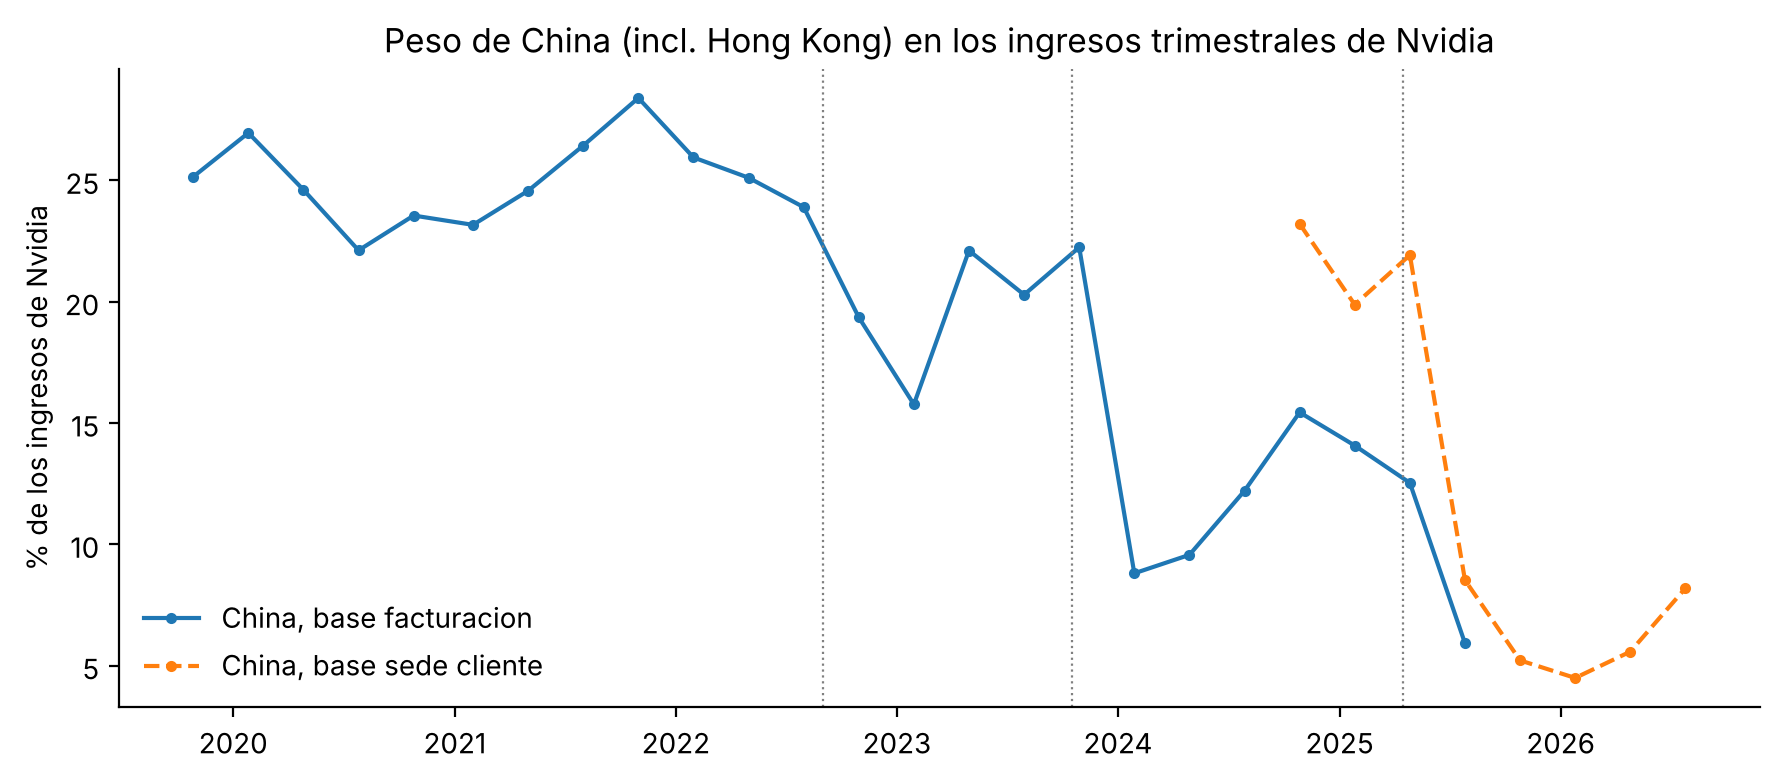

In [15]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 4))
for b, est in [('facturacion', '-'), ('sede_cliente', '--')]:
    s = nvda_q[nvda_q.base == b]
    ax.plot(s.fin, s.pct_china, est, marker='o', ms=3, label=f'China, base {b.replace("_", " ")}')
for f in ['2022-09-01', '2023-10-17', '2025-04-16']:
    ax.axvline(pd.Timestamp(f), color='grey', lw=0.8, ls=':')
ax.set_ylabel('% de los ingresos de Nvidia'); ax.set_title('Peso de China (incl. Hong Kong) en los ingresos trimestrales de Nvidia')
ax.legend(frameon=False); ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout(); fig.savefig(FIG / 'control_pct_china.png', dpi=150)